## Module 23: Principal Component Analysis

### Dataset: Wine Quality Dataset

In [1]:
# Done for you

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)

df = wine.frame

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### TODO 1: Explore the Dataset

In [2]:
# TODO

# Display dataset shape

# Display first few rows

# Display data types




In [3]:
df.shape

(178, 14)

In [4]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
df.dtypes

,0
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


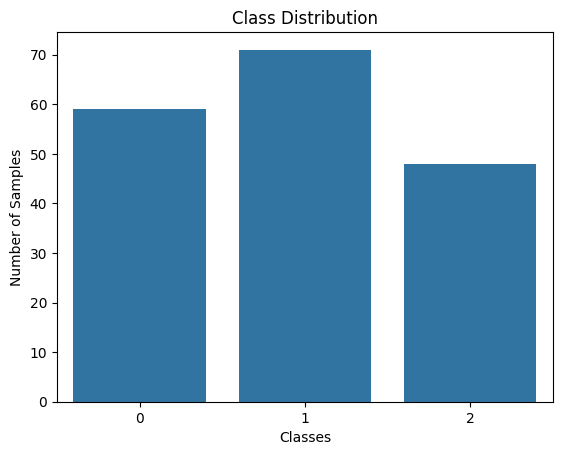

In [6]:
# Display class distribution?

sns.countplot(x='target', data=df)
plt.title('Class Distribution')
plt.xlabel('Classes')
plt.ylabel('Number of Samples')
plt.show()


### TODO 2 : Feature Correlation

In [7]:
# TODO

# Calculate correlation matrix
# Display highly correlated features

corr_matrix = df.corr()
print(corr_matrix)

                               alcohol  malic_acid       ash  \
alcohol                       1.000000    0.094397  0.211545   
malic_acid                    0.094397    1.000000  0.164045   
ash                           0.211545    0.164045  1.000000   
alcalinity_of_ash            -0.310235    0.288500  0.443367   
magnesium                     0.270798   -0.054575  0.286587   
total_phenols                 0.289101   -0.335167  0.128980   
flavanoids                    0.236815   -0.411007  0.115077   
nonflavanoid_phenols         -0.155929    0.292977  0.186230   
proanthocyanins               0.136698   -0.220746  0.009652   
color_intensity               0.546364    0.248985  0.258887   
hue                          -0.071747   -0.561296 -0.074667   
od280/od315_of_diluted_wines  0.072343   -0.368710  0.003911   
proline                       0.643720   -0.192011  0.223626   
target                       -0.328222    0.437776 -0.049643   

                              alcalinit

### TODO 3 : Standardization

In [8]:
from sklearn.preprocessing import StandardScaler
# Separate X and y

X = df.drop(['target'], axis = 1)
y = df['target']

In [9]:
# Apply StandardScaler
scaler = StandardScaler()

x_scaled = scaler.fit_transform(X)

### TODO 4 : Apply PCA

In [10]:
from sklearn.decomposition import PCA

In [11]:
# Apply PCA
np.set_printoptions(suppress=True)
pca_full = PCA(n_components=None)
X_pca_full = pca_full.fit_transform(x_scaled)


# Display number of principal components
explained = pca_full.explained_variance_ratio_

# Display explained variance ratio
explained

array([0.36198848, 0.1920749 , 0.11123631, 0.0706903 , 0.06563294,
       0.04935823, 0.04238679, 0.02680749, 0.02222153, 0.01930019,
       0.01736836, 0.01298233, 0.00795215])

### TODO 5 : Cumulative Variance

In [12]:
# TODO
# Calculate cumulative variance
# Plot cumulative variance graph

cum_verience = np.cumsum(explained)

cum_verience

array([0.36198848, 0.55406338, 0.66529969, 0.73598999, 0.80162293,
       0.85098116, 0.89336795, 0.92017544, 0.94239698, 0.96169717,
       0.97906553, 0.99204785, 1.        ])

### TODO 6 : Logistic Regression WITHOUT PCA

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [13]:
# TODO using pipeline perform these tasks


In [17]:
# Train-test split
X_train, X_test , y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [29]:
# StandardScaler
without_pca = Pipeline([
    ('scaling', StandardScaler()),
    ('cls', LogisticRegression(max_iter=5000)) # Logistic Regression
])

In [30]:
# Calculate Accuracy

without_pca.fit(X_train, y_train)
y_pred = without_pca.predict(X_test)

Accuracy_wiyhout_pca = accuracy_score(y_test, y_pred)
print('Accuracy Score : ', Accuracy_wiyhout_pca)

Accuracy Score :  0.9722222222222222


### TODO 7 : Logistic Regression WITH PCA

In [31]:
with_pca = Pipeline([
    ('scaling', StandardScaler()), # StandardScaler
    ('pca', PCA(n_components=0.95)), # PCA(95% rakhte joto gula component lage totogulo use kore)
    ('clf', LogisticRegression(max_iter=1000)) # Logistic Regression
])

In [32]:
# Calculate Accuracy
with_pca.fit(X_train,y_train)
y_pred = with_pca.predict(X_test)

accuracy_with_pca = accuracy_score(y_test, y_pred)
print('Accuracy Score with pca : ', accuracy_with_pca)

Accuracy Score with pca :  0.9722222222222222


### TODO 8 : Compare Results

In [15]:
# TODO

# Create a small comparison table

# Without PCA

# With PCA

# Accuracy

# Number of Features

Q: In this dataset, would you recomment PCA? Justify and explain your observation


A: